# 금리 급등기 미국 주택담보대출 15만 건으로 본 부도 위험 (Freddie Mac 2021~2023)

**질문**: 2022년 금리 급등 전후로 실행된 실제 주담대의 부도 위험은 어떻게 달라졌나? 과거 데이터로 만든 모델이 **미래 대출에서도 통하는가**? 그리고 **실제 손실액**으로 계산하면 어떤 승인 정책이 맞는가?

| 구분 | 내용 |
|---|---|
| 데이터 | [Freddie Mac Single-Family Loan-Level Dataset](https://freddiemac.com/research/datasets/sf-loanlevel-dataset) Release 48 (2026.10), 2021·2022·2023년 실행 대출 연도별 무작위 5만 건, 월별 상환 기록 2026년 6월까지 |
| 부도 정의 | 첫 납부 후 24개월 안에 90일 이상 연체 또는 부실 종료(제3자 매각·숏세일·REO·부실채권 매각). 코로나 상환유예·재난 기간 연체는 제외 |
| 검증 | **시간 기준(Out-of-Time)**: 2021~2022년 대출로 학습, 2023년 대출로 평가 |
| 모델 | WoE 스코어카드(운영) vs LightGBM(챌린저) |

> 방법론: Siddiqi, N. (2017). *Intelligent Credit Scoring* (2nd ed.). Wiley. · 데이터는 비상업·연구 목적 이용 조건에 따라 원본을 재배포하지 않습니다.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
import scorecard as sc, mortgage_model as mm

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
(ROOT / "reports/freddie").mkdir(parents=True, exist_ok=True)
Y = "default24_strict"

## 1. 데이터 확인

In [2]:
raw = pd.read_parquet(ROOT / "data/processed/freddie_loans.parquet")
print(f"전체 {len(raw):,}건 (연도별 {raw.groupby('vintage').size().to_dict()})")
d = mm.add_features(raw)
excl = {"결과 미확정(24개월 미관찰)": int((~d.observed).sum()),
        "신용점수·DTI 결측": int((d.observed & (d.fico.isna() | d.dti.isna())).sum())}
d = d[d.observed & d.fico.notna() & d.dti.notna()].reset_index(drop=True)
d[Y] = d[Y].astype(int)
print("제외:", excl, "→ 분석 대상", f"{len(d):,}건")

전체 150,000건 (연도별 {2021: 50000, 2022: 50000, 2023: 50000})
제외: {'결과 미확정(24개월 미관찰)': 474, '신용점수·DTI 결측': 44} → 분석 대상 149,482건


In [3]:
v = d.groupby("vintage").agg(
    대출수=("loan_id", "size"), 금리_중앙값=("rate", "median"), FICO_중앙값=("fico", "median"),
    DTI_중앙값=("dti", "median"), LTV_중앙값=("ltv", "median"), 대출금액_중앙값=("upb", "median"),
    부도율=(Y, "mean"), 부도율_유예포함=("default24", "mean"), 상환유예경험=("ever_relief", "mean"))
v

,대출수,금리_중앙값,FICO_중앙값,DTI_중앙값,LTV_중앙값,대출금액_중앙값,부도율,부도율_유예포함,상환유예경험
vintage,,,,,,,,,
2021,49892,2.9900,759.0000,35.0000,72.0000,"260,000.0000",0.0058,0.0100,0.0189
2022,49800,5.2500,751.0000,39.0000,80.0000,"270,000.0000",0.0145,0.0185,0.0280
2023,49790,6.7500,758.0000,40.0000,80.0000,"275,000.0000",0.0149,0.0177,0.0173


**금리 급등이 대출자 구성을 바꿨다.** 금리 중앙값은 2.99% → 5.25% → 6.75%로 두 배 넘게 올랐고, DTI도 35 → 40으로 높아졌다.
같은 기간 24개월 부도율은 **0.6% → 1.5%로 2.5배**가 됐다. 상환유예 기간 연체까지 넣으면 2021년 부도율이 거의 두 배로 부풀려진다(1.0%).
그래서 코로나 상환유예·재난 기간의 연체는 부도에서 제외했다.

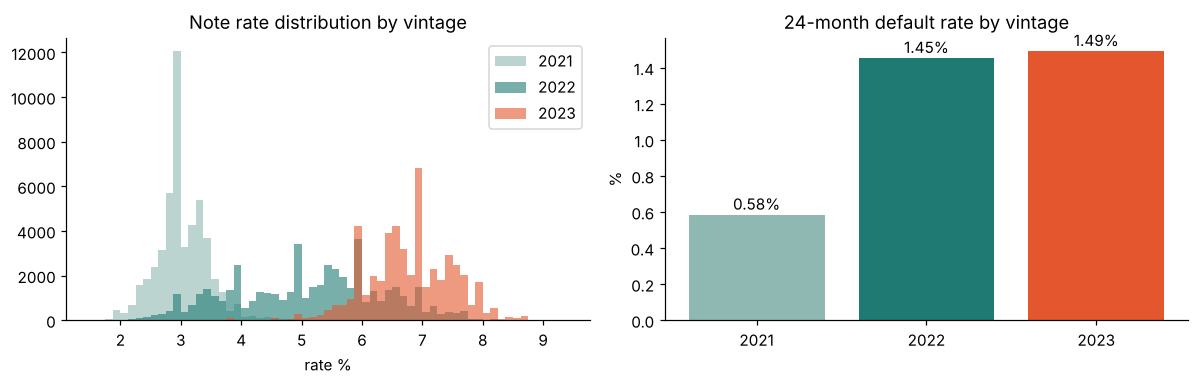

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for y_, c in zip([2021, 2022, 2023], ["#8FB8B2", "#1F7A73", "#E4572E"]):
    ax[0].hist(d.loc[d.vintage == y_, "rate"], bins=np.arange(1.5, 9.5, 0.125), alpha=.6, label=str(y_), color=c)
ax[0].set(title="Note rate distribution by vintage", xlabel="rate %"); ax[0].legend()
ax[1].bar(v.index.astype(str), v["부도율"] * 100, color=["#8FB8B2", "#1F7A73", "#E4572E"])
ax[1].set(title="24-month default rate by vintage", ylabel="%")
for i, r in enumerate(v["부도율"]): ax[1].text(i, r * 100 + .03, f"{r*100:.2f}%", ha="center")
plt.tight_layout(); plt.savefig(ROOT / "reports/freddie/vintage.png", bbox_inches="tight"); plt.show()

## 2. 무엇이 부도를 가르나

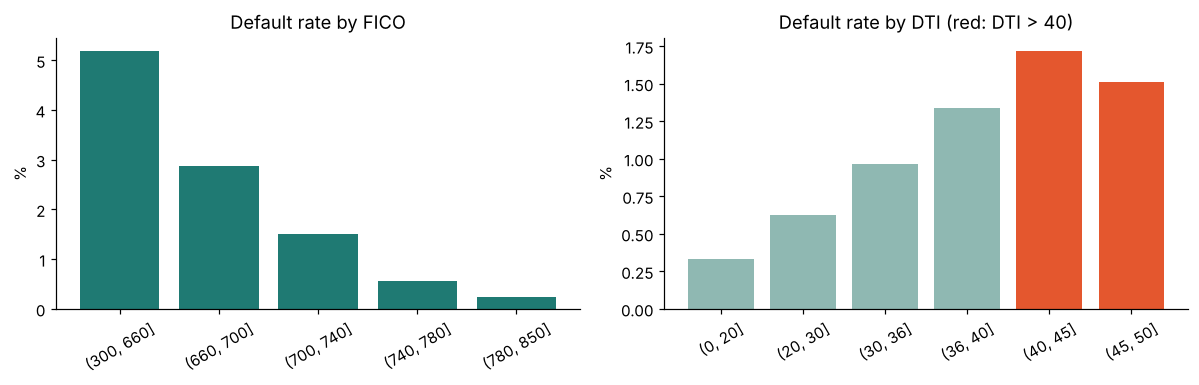

DTI 40 초과 vs 30 이하 부도율 배수: 2.97


In [5]:
def rate_by(col, q=None, bins=None):
    x = pd.cut(d[col], bins) if bins is not None else (pd.qcut(d[col], q, duplicates="drop") if q else d[col])
    t = d.groupby(x, observed=True)[Y].agg(대출수="size", 부도율="mean")
    return t
fico_t = rate_by("fico", bins=[300, 660, 700, 740, 780, 850])
dti_t = rate_by("dti", bins=[0, 20, 30, 36, 40, 45, 50])  # 프레디맥 매입 기준상 DTI는 최대 50
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(fico_t.index.astype(str), fico_t.부도율 * 100, color="#1F7A73"); ax[0].set(title="Default rate by FICO", ylabel="%")
ax[1].bar(dti_t.index.astype(str), dti_t.부도율 * 100, color=["#8FB8B2"] * 4 + ["#E4572E"] * 2)
ax[1].set(title="Default rate by DTI (red: DTI > 40)", ylabel="%")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(ROOT / "reports/freddie/fico_dti.png", bbox_inches="tight"); plt.show()
print("DTI 40 초과 vs 30 이하 부도율 배수:",
      round(d.loc[d.dti > 40, Y].mean() / d.loc[d.dti <= 30, Y].mean(), 2))

- **신용점수가 압도적이다.** FICO 660 이하는 780 초과보다 부도율이 열 배 이상 높다.
- **DTI가 40을 넘으면 부도율이 뚜렷이 오른다.** 한국이 은행권 DSR 한도를 40%로 두는 근거를 미국 실제 데이터로 확인할 수 있다(DTI는 주거비 중심, DSR은 전체 부채 원리금이라 정의는 다르다).

In [6]:
# 생애최초 구입자는 정말 위험한가? (단순 비교 vs 신용점수·LTV가 같은 사람끼리 비교)
raw_gap = d.groupby("first_time")[Y].mean()
d["fico_band"] = pd.cut(d.fico, [300, 700, 740, 780, 850]); d["ltv_band"] = pd.cut(d.ltv, [0, 80, 90, 200])
adj = d[d.first_time.isin(["Y", "N"])].groupby(["fico_band", "ltv_band", "first_time"], observed=True)[Y].mean().unstack()
w = d[d.first_time.isin(["Y", "N"])].groupby(["fico_band", "ltv_band"], observed=True).size()
adj_gap = (adj["Y"] - adj["N"]).mul(w).sum() / w.sum()
print(f"단순 비교: 생애최초 {raw_gap['Y']:.2%} vs 아님 {raw_gap['N']:.2%}  (차이 {raw_gap['Y']-raw_gap['N']:+.2%}p)")
print(f"신용점수·LTV 구간을 맞춘 비교: 차이 {adj_gap:+.2%}p")

단순 비교: 생애최초 1.43% vs 아님 1.08%  (차이 +0.35%p)
신용점수·LTV 구간을 맞춘 비교: 차이 -0.02%p


**생애최초 구입자 자체가 위험한 것은 아니다.** 단순 비교로는 부도율이 높아 보이지만, 신용점수와 LTV가 같은 사람끼리 비교하면 차이가 거의 사라진다.
위험은 '처음 산다'는 사실이 아니라 **낮은 신용점수와 높은 LTV**에서 온다. 한국의 생애최초 LTV 우대(6·27 대책 후 수도권 70%)처럼 첫 구입자를 지원하더라도, 신용점수·상환능력 심사를 함께 보면 위험을 관리할 수 있다는 시사점이다.

## 3. 분할: 시간 기준 검증

In [7]:
dev, oot = d[d.vintage <= 2022], d[d.vintage == 2023]
tr, va = train_test_split(dev, test_size=0.25, stratify=dev[Y], random_state=42)
pd.DataFrame({k: [len(x), x[Y].mean()] for k, x in [("학습(21~22)", tr), ("검증(21~22)", va), ("미래 검증 OOT(2023)", oot)]},
             index=["대출수", "부도율"]).T

,대출수,부도율
학습(21~22),"74,769.0000",0.0102
검증(21~22),"24,923.0000",0.0102
미래 검증 OOT(2023),"49,790.0000",0.0149


### 금리를 그대로 넣으면 안 되는 이유
금리 수준은 위험보다 **시기**를 더 많이 반영한다. 2023년 대출은 모두 6~7%대라 2021년 기준으로 학습한 모델에는 '전부 고위험'으로 보인다.
그래서 같은 분기에 실행된 대출의 중앙값 대비 **금리 가산폭**(위험에 따라 금리를 더 받은 정도)만 변수로 썼다.

In [8]:
print(f"분포 변화 PSI (학습 → 2023)  원시 금리: {sc.psi(tr.rate, oot.rate):.2f}   금리 가산폭: {sc.psi(tr.rate_spread, oot.rate_spread):.3f}")
print("PSI 기준: 0.1 미만 안정, 0.25 초과 심각")

분포 변화 PSI (학습 → 2023)  원시 금리: 6.49   금리 가산폭: 0.193
PSI 기준: 0.1 미만 안정, 0.25 초과 심각


## 4. 구간화 · IV · 스코어카드

In [9]:
bins = mm.fit_all(tr, tr[Y])
iv = pd.DataFrame({"변수": [mm.LABELS_KO[f] for f in bins], "IV": [b.iv for b in bins.values()]}, index=list(bins)).sort_values("IV", ascending=False)
iv["사용"] = np.where(iv.IV >= 0.02, "O", "제외(IV<0.02)")
iv

,변수,IV,사용
fico,신용점수(FICO),0.9974,O
dti,DTI(%),0.1933,O
rate_spread,"금리 가산폭(같은 분기 중앙값 대비, %p)",0.1788,O
borrowers,차주 수,0.1486,O
purpose,대출 목적,0.1409,O
log_upb,대출금액(로그),0.0703,O
ltv,LTV(%),0.0626,O
occupancy,거주 형태,0.0479,O
program,정책 프로그램,0.0317,O
prop_type,주택 유형,0.0167,제외(IV<0.02)


In [10]:
feats = [f for f in iv.index if bins[f].iv >= 0.02]
while True:
    lr = LogisticRegression(C=1.0, max_iter=2000).fit(mm.woe_frame(tr, bins, feats), tr[Y])
    wrong = [f for f, c in zip(feats, lr.coef_[0]) if c > 0]
    if not wrong: break
    print("부호 역전 제거:", wrong); feats = [f for f in feats if f not in wrong]
card = mm.build_card(bins, feats, lr.coef_[0], lr.intercept_[0], sc.Scaling(600, 50, 20))
print("최종 변수:", [mm.LABELS_KO[f] for f in feats])
pd.Series(lr.coef_[0], index=feats).round(3).to_frame("coef").T

최종 변수: ['신용점수(FICO)', 'DTI(%)', '금리 가산폭(같은 분기 중앙값 대비, %p)', '차주 수', '대출 목적', '대출금액(로그)', 'LTV(%)', '거주 형태', '정책 프로그램']


,fico,dti,rate_spread,borrowers,purpose,log_upb,ltv,occupancy,program
coef,-0.9110,-0.5270,-0.3860,-0.9730,-0.4210,-0.7640,-1.0620,-0.5650,-0.3090


## 5. LightGBM (챌린저)

In [11]:
X = lambda x: x[mm.NUMERIC + mm.CATEGORICAL].astype({c: "category" for c in mm.CATEGORICAL})
gbm = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=200,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
gbm.fit(X(tr), tr[Y], eval_X=X(va), eval_y=va[Y], callbacks=[lgb.early_stopping(150, verbose=False)])
print("best iteration", gbm.best_iteration_)

best iteration 248


## 6. 미래 대출(2023)에서도 통하는가

In [12]:
s = {k: mm.score_frame(card, x) for k, x in [("tr", tr), ("va", va), ("oot", oot)]}
p_sc = {k: mm.to_pd(v, card["scaling"]) for k, v in s.items()}
p_gb = {"va": gbm.predict_proba(X(va))[:, 1], "oot": gbm.predict_proba(X(oot))[:, 1]}
def m(y, p): a = roc_auc_score(y, p); return {"AUC": a, "Gini": 2 * a - 1, "KS": sc.ks_stat(y, p)}
perf = pd.DataFrame({
    "스코어카드 · 검증(21~22)": m(va[Y], p_sc["va"]), "스코어카드 · 2023": m(oot[Y], p_sc["oot"]),
    "LightGBM · 2023": m(oot[Y], p_gb["oot"]), "FICO 단독 · 2023": m(oot[Y], -oot.fico)}).T
perf["PSI(학습→2023)"] = [np.nan, sc.psi(s["tr"], s["oot"]), np.nan, np.nan]
perf

,AUC,Gini,KS,PSI(학습→2023)
스코어카드 · 검증(21~22),0.8081,0.6162,0.4927,NaN
스코어카드 · 2023,0.7986,0.5971,0.4721,0.0224
LightGBM · 2023,0.8095,0.6190,0.4884,NaN
FICO 단독 · 2023,0.7703,0.5405,0.4487,NaN


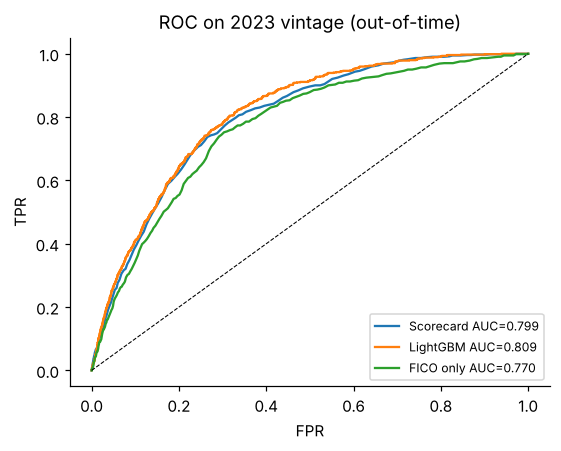

In [13]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for name, p in [("Scorecard", p_sc["oot"]), ("LightGBM", p_gb["oot"]), ("FICO only", -oot.fico.values)]:
    f, t, _ = roc_curve(oot[Y], p); ax.plot(f, t, label=f"{name} AUC={roc_auc_score(oot[Y], p):.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=.7); ax.set(title="ROC on 2023 vintage (out-of-time)", xlabel="FPR", ylabel="TPR"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / "reports/freddie/roc_oot.png", bbox_inches="tight"); plt.show()

학습에 쓰지 않은 **미래(2023) 대출**에서도 AUC가 거의 떨어지지 않았다. 순위를 매기는 능력은 시간이 지나도 유지된다.
LightGBM의 우위는 작고, 둘 다 신용점수만 쓴 경우보다 확실히 낫다.

## 7. 그런데 부도 '수준'은 틀렸다: 금리 급등 후 재보정

In [14]:
cal = pd.DataFrame({"예측 부도율": [p_sc["va"].mean(), p_sc["oot"].mean()], "실제 부도율": [va[Y].mean(), oot[Y].mean()]},
                   index=["검증(21~22)", "2023"])
cal["실제/예측"] = cal["실제 부도율"] / cal["예측 부도율"]
cal

,예측 부도율,실제 부도율,실제/예측
검증(21~22),0.0102,0.0102,0.9930
2023,0.0103,0.0149,1.4419


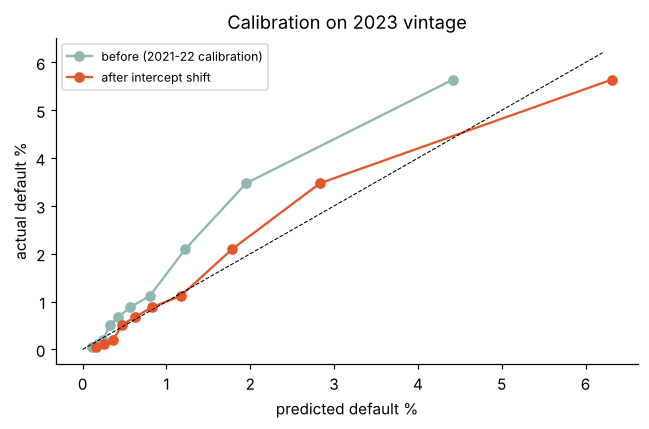

절편 조정폭 +0.382 (log-odds) = 점수 +11.0점


In [15]:
# 점수 구간별 예측 vs 실제 (2023)
g = pd.qcut(s["oot"], 10, duplicates="drop")
dec = pd.DataFrame({"pred": p_sc["oot"], "act": oot[Y].values, "g": g}).groupby("g", observed=True).mean()
# 절편만 조정해 최신 부도 수준에 맞추기 (순위는 그대로)
shift = np.log(oot[Y].mean() / (1 - oot[Y].mean())) - np.log(p_sc["va"].mean() / (1 - p_sc["va"].mean()))
recal = 1 / (1 + np.exp(-(np.log(p_sc["oot"] / (1 - p_sc["oot"])) + shift)))
dec["recal"] = pd.DataFrame({"r": recal, "g": g}).groupby("g", observed=True).r.mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(dec.pred * 100, dec.act * 100, "o-", label="before (2021-22 calibration)", color="#8FB8B2")
ax.plot(dec.recal * 100, dec.act * 100, "o-", label="after intercept shift", color="#E4572E")
mx = dec.act.max() * 110; ax.plot([0, mx], [0, mx], "k--", lw=.7)
ax.set(xlabel="predicted default %", ylabel="actual default %", title="Calibration on 2023 vintage"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / "reports/freddie/calibration.png", bbox_inches="tight"); plt.show()
print(f"절편 조정폭 {shift:+.3f} (log-odds) = 점수 {shift * card['scaling']['pdo'] / np.log(2):+.1f}점")

모델은 **누가 더 위험한지는 맞혔지만, 2023년 전체 부도 수준은 약 30% 낮게 예측**했다. 고금리로 같은 점수대의 부도율이 올랐기 때문이다.
실무에서는 모델을 다시 만들지 않고 **절편(기준 부도율)만 최신 실적에 맞춰 재보정**한다. 승인 기준점도 이 재보정분만큼 올려야 같은 위험 수준이 유지된다.

## 8. 실제 손실액으로 본 손익

프레디맥 데이터에는 부실 대출이 정리(매각·REO)될 때의 **실제 손실액**이 있다.

In [16]:
dd = d[d[Y] == 1]
liq = d[d.liquidated & d.zb_upb.notna()]
sev = (liq.actual_loss.sum() / liq.zb_upb.sum())
realized = dd.actual_loss.fillna(0).sum() / dd.upb.sum()
loss_stats = {"부도 대출 수": len(dd), "2026.6까지 청산된 비율": dd.liquidated.mean(),
              "청산 시 손실률(금액가중)": sev, "청산 손실률 중앙값": (liq.actual_loss / liq.zb_upb).median(),
              "부도 대출 원금 대비 실현 손실": realized}
pd.Series(loss_stats).to_frame("값")

,값
부도 대출 수,"1,756.0000"
2026.6까지 청산된 비율,0.0706
청산 시 손실률(금액가중),0.0992
청산 손실률 중앙값,0.0391
부도 대출 원금 대비 실현 손실,0.0071


24개월 안에 부도가 난 대출 중 **실제로 청산된 것은 소수**이고, 대부분은 정상화·채무조정으로 이어졌다. 집값 상승기여서 청산되더라도 손실률이 낮다.
그래서 **손실률(LGD) 가정에 따라 최적 정책이 크게 달라진다.** 아래에서 세 가지 시나리오로 비교한다.
- **실현 기준**: 2026년 6월까지 실제 확정된 손실 (아직 정리 중인 대출이 있어 하한값)
- **청산 기준**: 부도 대출이 모두 청산된다고 볼 때의 손실률
- **위기 가정 40%**: 2008년 금융위기 수준의 집값 하락을 가정한 값 (데이터가 아닌 가정)

In [17]:
MARGIN = 0.01   # 대출 원금 대비 연 순이익 1% 가정 (2년 보유)
scen = {"실현 기준": max(realized, 0.001), "청산 기준": sev, "위기 가정 40%": 0.40}
def pnl_by_cut(score, y, upb, lgd, cuts):
    score, y, upb = map(np.asarray, (score, y, upb)); rows = []
    for c in cuts:
        a = score >= c
        gain = (upb * MARGIN * 2)[a & (y == 0)].sum(); loss = (upb * lgd)[a & (y == 1)].sum()
        rows.append({"cutoff": c, "승인율": a.mean(), "승인 부도율": y[a].mean() if a.any() else 0,
                     "손익(대출 100만 달러당)": (gain - loss) / upb.sum() * 1e6})
    return pd.DataFrame(rows)
cuts = np.arange(int(s["oot"].min()), int(s["oot"].max()) + 1)
res = {}
for k, lgd in scen.items():
    t = pnl_by_cut(s["oot"], oot[Y], oot.upb, lgd, cuts); b = t.loc[t["손익(대출 100만 달러당)"].idxmax()]
    base = t.iloc[0]
    res[k] = {"LGD": lgd, "최적 기준점": int(b.cutoff), "승인율": b["승인율"], "승인 부도율": b["승인 부도율"],
              "손익(100만$당)": b["손익(대출 100만 달러당)"], "전원 승인 손익": base["손익(대출 100만 달러당)"]}
res = pd.DataFrame(res).T; res

,LGD,최적 기준점,승인율,승인 부도율,손익(100만$당),전원 승인 손익
실현 기준,0.0071,527.0000,1.0000,0.0149,"19,619.4230","19,619.4230"
청산 기준,0.0992,527.0000,1.0000,0.0149,"18,325.7236","18,325.7236"
위기 가정 40%,0.4000,587.0000,0.9281,0.0111,"14,517.3383","14,101.2017"


**손실률 가정이 승인 정책을 좌우한다.** 집값이 오르던 2021~2023년 실적 그대로라면 거의 모든 대출을 승인하는 것이 최적이다.
위기 수준의 손실을 가정하면 기준점을 크게 올려야 한다. 그래서 실무에서는 **최근 실적(실현 LGD)만 보고 정책을 느슨하게 하지 않고**, 스트레스 시나리오를 함께 본다.
한국의 **스트레스 DSR**도 같은 발상이다. 지금 금리가 아니라 금리가 오를 때를 가정해서 한도를 정한다.

## 9. 앱용 집계 저장

In [18]:
sc.save_json(card, ROOT / "models/mortgage_scorecard.json")
oot_s = pd.DataFrame({"score": s["oot"].astype(int), "y": oot[Y].values, "upb": oot.upb.values})
agg = oot_s.groupby("score").agg(n=("y", "size"), bad=("y", "sum"), upb=("upb", "sum"),
                                 upb_bad=("upb", lambda u: u[oot_s.loc[u.index, "y"] == 1].sum())).reset_index()
art = {
    "meta": {"source": "Freddie Mac SFLLD Release 48 (2026.10) sample, vintages 2021-2023", "target": "24개월 내 90일+ 연체·부실 종료 (상환유예·재난 제외)",
             "n_dev": int(len(dev)), "n_oot": int(len(oot)), "margin": MARGIN},
    "vintage": v.reset_index().to_dict("records"),
    "fico": fico_t.reset_index().astype({"fico": str}).to_dict("records"),
    "dti": dti_t.reset_index().astype({"dti": str}).to_dict("records"),
    "first_time": {"raw_gap": float(raw_gap["Y"] - raw_gap["N"]), "adjusted_gap": float(adj_gap)},
    "perf": perf.reset_index().rename(columns={"index": "model"}).to_dict("records"),
    "psi": {"raw_rate": float(sc.psi(tr.rate, oot.rate)), "rate_spread": float(sc.psi(tr.rate_spread, oot.rate_spread)),
            "score": float(sc.psi(s["tr"], s["oot"]))},
    "calibration": {"pred_dev": float(p_sc["va"].mean()), "pred_oot": float(p_sc["oot"].mean()),
                    "act_oot": float(oot[Y].mean()), "shift_logodds": float(shift)},
    "loss": {k: float(v_) for k, v_ in loss_stats.items()}, "scenarios": res.reset_index().rename(columns={"index": "scenario"}).to_dict("records"),
    "score_agg_oot": agg.to_dict("records"),
    "lgbm_best_iter": int(gbm.best_iteration_),
}
sc.save_json(art, ROOT / "models/mortgage_artifacts.json")
print("saved", (ROOT / "models/mortgage_artifacts.json").stat().st_size // 1024, "KB")

saved 25 KB


## 10. 결론

**결과 (2023년 대출 49,790건, 학습에 쓰지 않은 미래 데이터)**
1. **금리 급등은 실제로 부도를 늘렸다.** 금리 중앙값이 2.99%(2021)에서 6.75%(2023)로 오르는 동안 24개월 부도율은 0.58%에서 1.49%로 약 2.5배가 됐다.
2. **모델은 시간이 지나도 순위를 잘 맞혔다.** 스코어카드 AUC는 2021~22년 검증 0.808, 2023년 0.799로 거의 그대로다. LightGBM(0.810)과의 차이는 작고, 둘 다 신용점수만 쓴 경우(0.770)보다 낫다.
3. **하지만 부도 수준은 약 30% 낮게 예측했다.** 실제 1.49% 대비 예측 1.03%. 고금리로 같은 점수대의 위험이 올랐기 때문이다. 절편만 최신 실적으로 재보정하면 되고, 같은 위험을 유지하려면 승인 기준점을 **약 11점** 올려야 한다.
4. **금리는 수준이 아니라 가산폭으로 써야 한다.** 원시 금리는 시기 차이 때문에 분포가 완전히 달라졌고(PSI 6.49), 같은 분기 대비 가산폭으로 바꾸면 0.19로 안정된다.
5. **DTI 40 초과 대출의 부도율은 DTI 30 이하의 약 3배**다. 한국 은행권 DSR 40% 한도의 근거를 미국 실제 데이터로 확인할 수 있다.
6. **생애최초 구입자 자체는 위험하지 않다.** 단순 비교로는 0.35%p 높지만, 신용점수·LTV를 맞추면 차이가 사라진다(−0.02%p).
7. **실제 손실은 매우 작았다.** 부도 대출 중 2026년 6월까지 청산된 것은 7%뿐이고, 청산되더라도 손실률은 약 10%였다. 집값 상승기의 실적만 보면 거의 전원 승인이 최적이다. 하지만 위기 수준(손실률 40%)을 가정하면 기준점을 올려야 손익이 낫다. 그래서 정책은 최근 실적이 아니라 **스트레스 시나리오**로 정해야 한다.

**한계**
- 프레디맥이 매입한 대출만 있어 **거절된 신청자의 결과는 알 수 없다.** 여기서 말하는 '승인 정책'은 이미 승인된 대출 중 어디까지 더 걸러낼지에 대한 분석이다.
- 연도별 5만 건 샘플이며, 실제 손실은 아직 정리 중인 대출이 있어 하한값이다.
- 순이익률(연 1%)과 위기 손실률(40%)은 가정값이다.